# Region-of-interest analysis

A region of interest (ROI) combines several measurement channels into one regional signal. Here we create two regions, compare averaging choices, and analyze regional responses to a simulated task. Original channel data stay in the recording.

This example averages **time courses**. Averaging statistical results from an already fitted channel model will be added separately.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyBrainAnalyzIR.testing import simData
from pyBrainAnalyzIR.sigproc.roi import roi_average
from pyBrainAnalyzIR.pipelines.modules.roi import ROIAverage
from pyBrainAnalyzIR.pipelines.modules import preproccessing as prep
from pyBrainAnalyzIR.pipelines.modules.filters import bandpass_filter
from pyBrainAnalyzIR.pipelines.modules.motion_correction import TDDR
from pyBrainAnalyzIR.pipelines.modules.glm import GLM

dset, truth = simData.simdataset(num_files=5, snr=10, random_seed=2026)
rec = dset.dataset[0]
original_amp = rec['amp'].copy(deep=True)

 94%|█████████▍| 15/16 [00:00<00:00, 3942.02it/s]


## Define regions

Each row identifies a source-detector pair and the region it belongs to. The weight controls its relative contribution. Here, the first channel belongs to both regions and has twice the table weight of the other members. Select both regions in the plot below to see its blended color. These region names are illustrative, not anatomical registrations.

In [2]:
roi_table = pd.DataFrame({
    'source': rec['amp'].source.values[[0, 1, 2, 0, 3, 4]],
    'detector': rec['amp'].detector.values[[0, 1, 2, 0, 3, 4]],
    'weight': [2, 1, 1, 2, 1, 1],
    'name': ['Region A'] * 3 + ['Region B'] * 3,
})
roi_table

,source,detector,weight,name
0,S1,D1,2,Region A
1,S2,D1,1,Region A
2,S2,D2,1,Region A
3,S1,D1,2,Region B
4,S3,D2,1,Region B
5,S3,D3,1,Region B


## Average and compare

By default, channels with lower temporal variance receive more weight. Set `weighted=False` to use only the weights in your table. Both results can live alongside the original `amp` data, under separate named ROI definitions.

Masked or missing samples are left out and the remaining contributions are renormalized. If all contributing channels are bad, the regional sample is marked bad too.

Click the region buttons below the probe to toggle regions on or off (at least one stays selected). Each region has a fixed color shared by its signal and contributing probe channels. Smaller membership weights produce paler channels; channels shared by selected regions blend their colors. These shades represent the weights in your ROI table, not variance weighting. The interactive plot uses the Jupyter widget backend (`ipympl`).

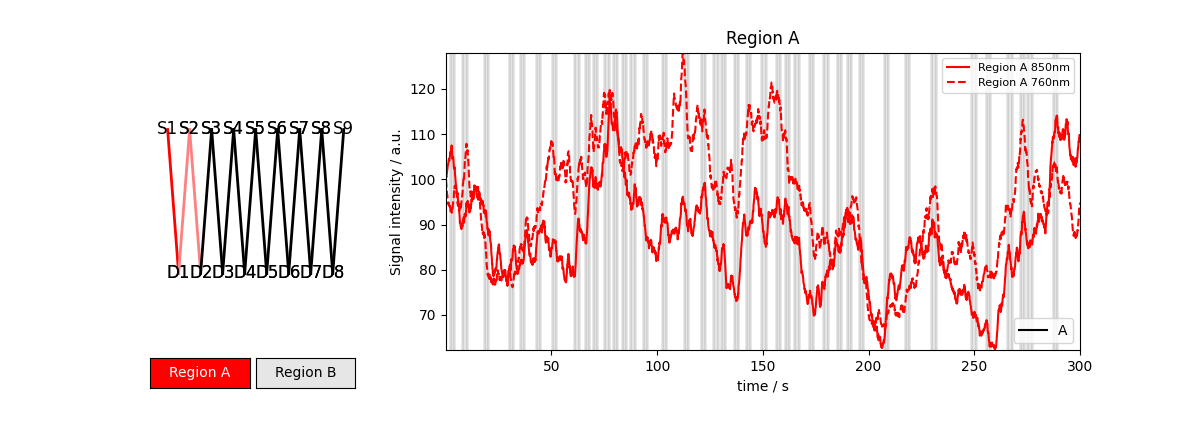

In [3]:
job = ROIAverage()
job.options['roi_table'] = roi_table
job.run(dset)  # adds amp_roi, using the default inverse-variance weighting

roi_average(dset, roi_table, output_name='amp_roi_equal',
            roi_name='equal_weights', weighted=False)
assert rec['amp'].identical(original_amp)
assert set(rec.aux_obj['roi_definitions']) == {'default', 'equal_weights'}

%matplotlib widget
from pyBrainAnalyzIR.vis.plot_nirs_inline import plot as nirs_show

roi_figure = nirs_show(rec, type='amp_roi')
# To view the average without variance weighting instead:
# nirs_show(rec, type='amp_roi_equal')

In [4]:
from pyBrainAnalyzIR.dataclasses.roi import get_geo_roi

geo = get_geo_roi(rec, rec["amp_roi"])

In [5]:
geo

GeoROI(name='default', membership=  source detector  weight      name
0     S1       D1     2.0  Region A
1     S2       D1     1.0  Region A
2     S2       D2     1.0  Region A
3     S1       D1     2.0  Region B
4     S3       D2     1.0  Region B
5     S3       D3     1.0  Region B, distances=<xarray.DataArray (channel: 2)> Size: 16B
<Quantity([31.6227766 31.6227766], 'millimeter')>
Coordinates:
  * channel  (channel) <U8 64B 'Region A' 'Region B', weights=<xarray.DataArray (channel: 2, source_channel: 16, wavelength: 2)> Size: 512B
array([[[0.54466431, 0.6141376 ],
        [0.29370391, 0.25186203],
        [0.16163178, 0.13400037],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.        , 0.        ],
        [0.     

## Analyze regional signals

Choose the regional input and output names just as you would choose channel time courses. We resample, convert to optical density, filter, repair motion, convert to hemoglobin concentration, and fit a task model. Each output keeps its ROI identity; the original channel signals and their masks are unchanged.

Averaging intensity before conversion is not the same as averaging concentration afterward. For a concentration-based regional summary, first preprocess and convert each channel, then average the concentration time courses. Short-separation regression should also be performed in channel space before averaging.

 50%|█████     | 1/2 [00:00<00:00, 394.94it/s]


,Channel,Type,Condition,Beta,StdErr,T-value,P-values,Q-values
0,Region A,HbO,HRF A,-0.763070,0.217729,-3.504672,0.000474,0.002756
1,Region A,HbO,Drift 0,0.225519,0.120949,1.864585,0.062484,0.083312
2,Region A,HbR,HRF A,0.521426,0.157642,3.307655,0.000969,0.002756
3,Region A,HbR,Drift 0,-0.214744,0.087570,-2.452246,0.014339,0.025955
4,Region B,HbO,HRF A,-0.539318,0.163961,-3.289307,0.001034,0.002756
5,Region B,HbO,Drift 0,0.132533,0.091080,1.455119,0.145898,0.145898
6,Region B,HbR,HRF A,0.399487,0.165949,2.407288,0.016222,0.025955
7,Region B,HbR,Drift 0,-0.135509,0.092185,-1.469972,0.141832,0.145898


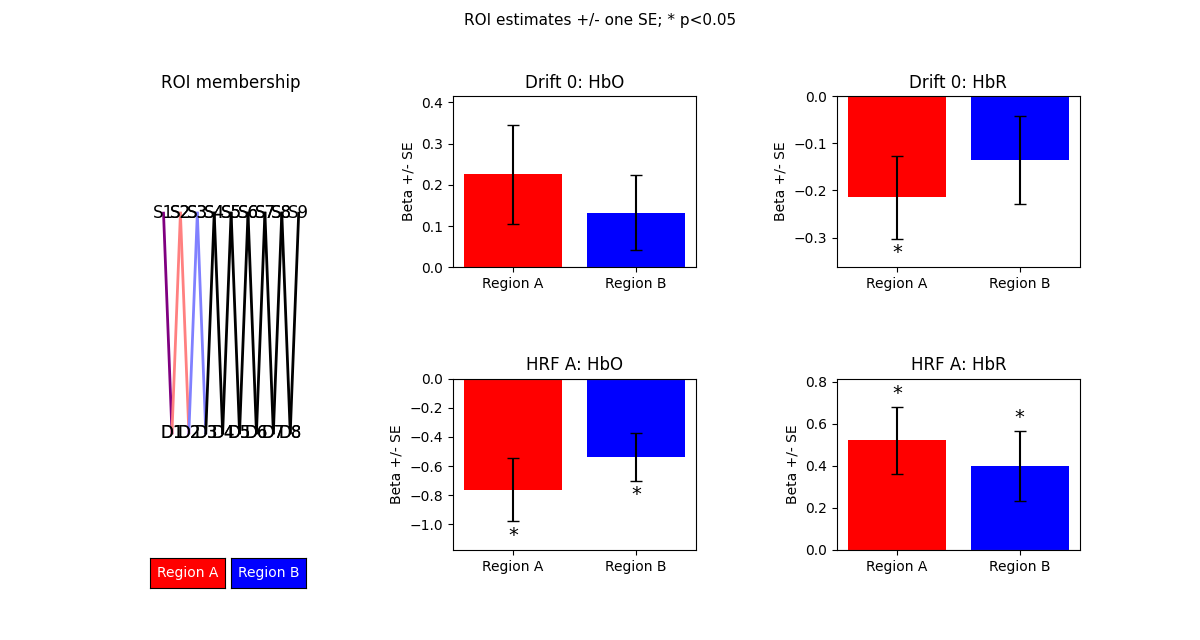

In [6]:
steps = [
    (prep.resample(), 'amp_roi', 'amp_roi_rs'),
    (prep.intensity_opticaldensity(), 'amp_roi_rs', 'od_roi'),
    (bandpass_filter(), 'od_roi', 'od_roi_filtered'),
    (TDDR(), 'od_roi_filtered', 'od_roi_repaired'),
    (prep.mbll(), 'od_roi_repaired', 'conc_roi'),
    (GLM(), 'conc_roi', 'stats_roi'),
]
for step, source, destination in steps:
    step.inputName = source
    step.outputName = destination
    if isinstance(step, GLM):
        step.options['noise_model'] = 'ols'
    step.run(dset)

assert rec['amp'].identical(original_amp)
assert rec['stats_roi'].geoROI.region_names == ['Region A', 'Region B']
results = rec['stats_roi'].table()
display(results)

# Draw every condition, with separate HbO and HbR panels.
individual_figure = rec['stats_roi'].draw(thresh='p<0.05')
plt.show()

The results table uses region names in its Channel column. Beta describes the estimated task response, while the other columns describe uncertainty and statistical evidence. This is a GLM fitted to regional time courses, not an average of previously fitted channel statistics.

In the figure, bar heights show beta and error bars show one standard error (not a confidence interval). A star marks a response meeting the requested significance threshold. Each task condition and hemoglobin type gets its own panel. One shared probe shows the contributing channels, with the same weight shading and blended overlap colors as the time-course plot. The colored region labels below it are a fixed color key: clicking them does not hide regions.

## Combine participants

The regional GLM results can enter a group mixed-effects model. Each participant must use the same ROI definitions. The default group model estimates an average response for each task condition. The group figure uses the same display, but its bars and standard errors now describe the group estimates. Here we request `q<0.05` to mark responses surviving false-discovery-rate correction across all estimates; use `p<0.05` for uncorrected significance.

,Channel,Type,Condition,Beta,StdErr,T-value,P-values,Q-values
0,Region A,HbO,Condition[HRF A],0.198650,0.179062,1.109392,0.329463,0.439285
1,Region B,HbO,Condition[HRF A],0.018259,0.158737,0.115024,0.913969,0.913969
2,Region A,HbR,Condition[HRF A],-0.189346,0.125275,-1.511435,0.205209,0.439285
3,Region B,HbR,Condition[HRF A],-0.151991,0.125330,-1.212723,0.291958,0.439285


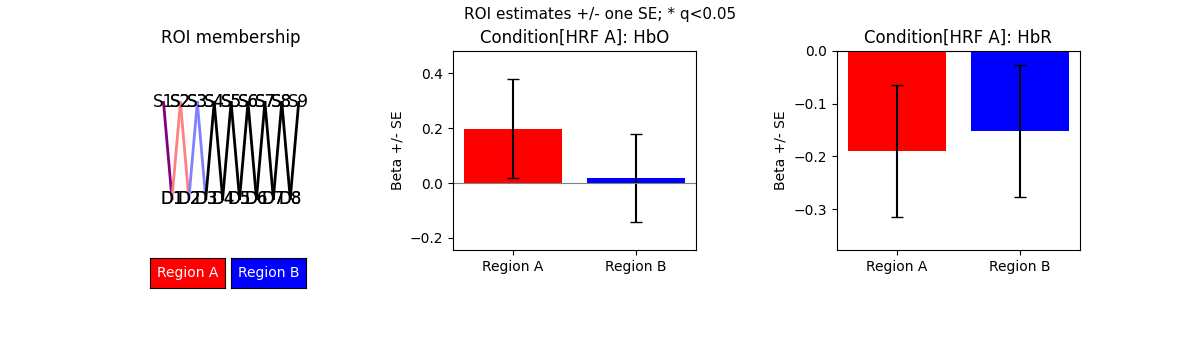

In [7]:
from pyBrainAnalyzIR.pipelines.modules.mixedeffects import MixedEffects

group = MixedEffects()
group.inputName = 'stats_roi'
group.outputName = 'groupstats_roi'
group.options['robust'] = False
group.run(dset)
group_results = dset['groupstats_roi']
assert group_results.geoROI.region_names == ['Region A', 'Region B']
display(group_results.table())
group_figure = group_results.draw(thresh='q<0.05')
plt.show()

## Compare ROI before GLM and ROI after GLM

There are two ways to obtain a regional response: average the channel signals first and fit the regional GLM, or fit each channel first and pool its fitted responses afterward. Statistics pooling applies the same spatial weights to beta and propagates the **full covariance matrix**, including correlations between channels, regions, hemoglobin types, and task conditions. It does not average standard errors.

For an ordinary least-squares (OLS) model, these operations agree when all channels use the same model design and valid samples and the same fixed spatial weights. We therefore use `weighted=False` in both paths below. This still respects the weights in our membership table. With `weighted=True`, the signal average uses temporal variance whereas the statistics average uses fitted coefficient variance, so these are generally different weights and need not agree even for OLS. Channel-specific missing samples or regressors can also break the equivalence.

To make a fair comparison, we first convert the physical channels to concentration, then run both paths on that same input. Averaging intensity before conversion, as in the earlier pipeline, would be a different comparison.

In [8]:
import copy

comparison_rec = copy.deepcopy(rec)
# Keep only the physical channels used in this small demonstration.
comparison_rec['amp_compare'] = rec['amp'].isel(channel=slice(0, 6)).copy(deep=True)
for module, source, target in [
    (prep.resample(), 'amp_compare', 'amp_compare_rs'),
    (prep.intensity_opticaldensity(), 'amp_compare_rs', 'od_compare'),
    (prep.mbll(), 'od_compare', 'conc_compare'),
]:
    module.inputName, module.outputName = source, target
    if isinstance(module, prep.resample):
        module.options['Fs'] = 2
    module.run(comparison_rec)

roi_average(comparison_rec, roi_table, input_name='conc_compare',
            output_name='conc_compare_roi', roi_name='before_glm', weighted=False)
comparison_summary = []
for model in ['ols', 'ar_irls']:
    # Path 1: ROI time course, then GLM.
    before_job = GLM()
    before_job.options['noise_model'] = model
    before_job.inputName = 'conc_compare_roi'
    before_job.outputName = f'roi_then_{model}'
    before_job.run(comparison_rec)

    # Path 2: channel GLM, then pool its coefficients and covariance.
    channel_job = GLM()
    channel_job.options['noise_model'] = model
    channel_job.inputName = 'conc_compare'
    channel_job.outputName = f'channel_{model}'
    channel_job.run(comparison_rec)
    pool_job = ROIAverage()
    pool_job.inputName = f'channel_{model}'
    pool_job.outputName = f'{model}_then_roi'
    pool_job.options.update(roi_table=roi_table, roi_name=f'after_{model}', weighted=False)
    pool_job.run(comparison_rec)

    before = comparison_rec[f'roi_then_{model}']
    after = comparison_rec[f'{model}_then_roi']
    if model == 'ols':
        np.testing.assert_allclose(before.betas, after.betas, rtol=1e-10, atol=1e-12)
        np.testing.assert_allclose(before.covariance, after.covariance, rtol=1e-9, atol=1e-12)
    comparison_summary.append({
        'Model': model,
        'Largest beta difference': np.max(np.abs(before.betas.values - after.betas.values)),
        'Largest SE difference': np.max(np.abs(before.table()['StdErr'] - after.table()['StdErr'])),
        'Relative beta difference': np.linalg.norm(before.betas - after.betas) / np.linalg.norm(before.betas),
    })
display(pd.DataFrame(comparison_summary))
print('OLS coefficients and full covariance agree to numerical precision.')

 83%|████████▎ | 5/6 [00:00<00:00, 17.81it/s]


,Model,Largest beta difference,Largest SE difference,Relative beta difference
0,ols,4.440892e-16,5.551115e-17,2.393053e-16
1,ar_irls,5.695901e-02,1.254273e-02,1.469881e-02


OLS coefficients and full covariance agree to numerical precision.


AR-IRLS estimates its noise model and robust weights separately for each signal. Combining channels changes those estimates, so the two orders generally give similar but not identical results; the size of the difference depends on the data. The table above measures the actual difference in this example rather than assuming equality. The figure below shows the post-GLM pooled results with the same probe, beta/error bars, and significance stars used earlier.

You can feed the post-GLM regional statistics into the mixed-effects module just like statistics from regional time courses. `ROIAverage` accepts a recording or dataset with a statistics input name, and `roi_average(channel_stats, roi_table, weighted=False)` returns a new pooled Statistics object without changing the channel results. Keep the same ROI definitions and analysis approach across participants.

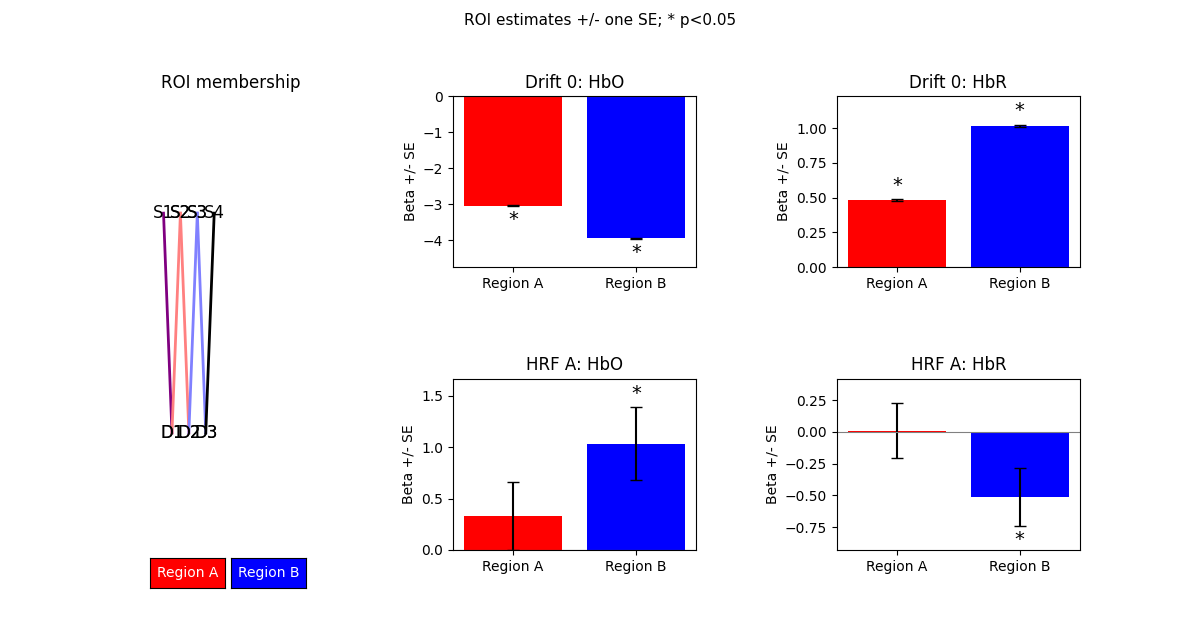

In [9]:
pooled_statistics_figure = comparison_rec['ar_irls_then_roi'].draw(thresh='p<0.05')
plt.show()

## Regional resting-state connectivity

Connectivity summarizes how signals vary together. We generate two separate resting recordings without task responses, convert the channel signals to hemoglobin concentration, and average them into the same regions. The connectivity module then takes `conc_roi` directly. The result is an ROI-to-ROI adjacency matrix, rather than a channel-to-channel matrix.

Short-separation correction must be done on physical channels before ROI averaging. It is disabled here because these simulated recordings have no superficial signal model. AR prewhitening and robust correlation are enabled to reduce the influence of serially correlated noise and outliers.

Matrix colors show correlation coefficients, including nonsignificant values. A star marks `p<0.05`; choose `threshold_type='q'` for false-discovery-rate correction. The diagonal shows each ROI's correlation with itself and is never starred. The companion probe uses the same ROI membership colors and fixed color labels as the statistics figures. Overlapping ROIs share measurements, so correlation between them need not reflect an independent physiological connection.

To,Region A,Region B
From,,
Region A,1.000000,0.691132
Region B,0.691132,1.000000


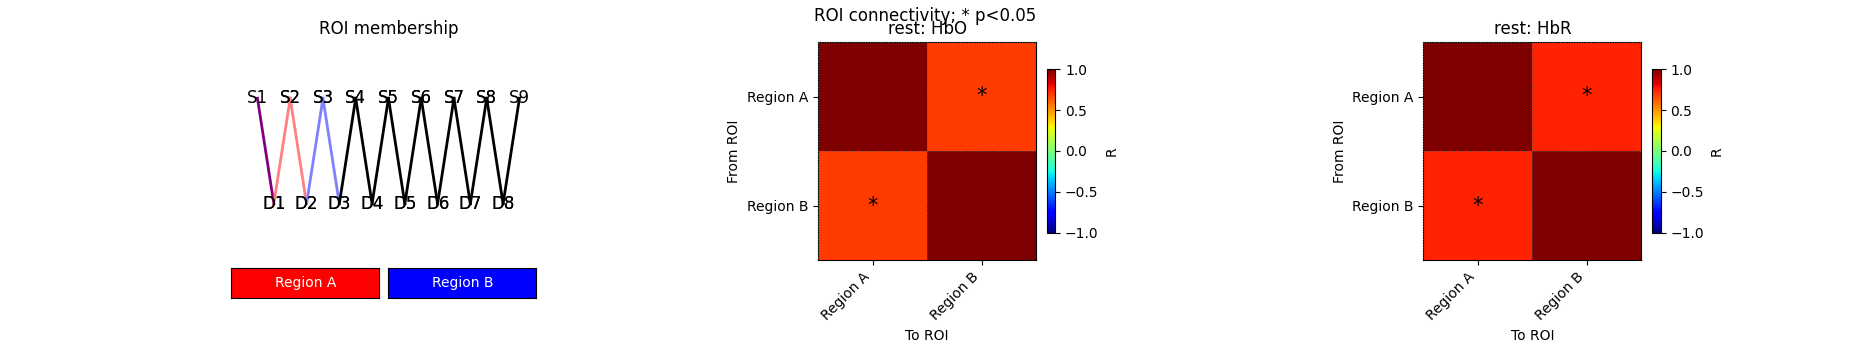

In [10]:
from pyBrainAnalyzIR.dataclasses.dataset import DataSet
from pyBrainAnalyzIR.pipelines.modules.connectivity import resting_state_connectivity, hyperscanning

rest_recordings = [simData.ARnoise(random_seed=seed) for seed in (501, 502)]
for index, recording in enumerate(rest_recordings):
    recording.meta_data.update(subject=f'Person {index + 1}', pair='Example pair')
rest_dset = DataSet(rest_recordings)
for module, source, target in [
    (prep.intensity_opticaldensity(), 'amp', 'od'),
    (prep.mbll(), 'od', 'conc'),
]:
    module.inputName, module.outputName = source, target
    module.run(rest_dset)
roi_average(rest_dset, roi_table, input_name='conc', output_name='conc_roi')

rest_job = resting_state_connectivity()
rest_job.inputName = 'conc_roi'
rest_job.options['short_separation_correction'] = False
rest_job.options['AR'] = 4
rest_job.run(rest_dset)
roi_conn = rest_dset.dataset[0]['conn']
display(roi_conn.matrix(type_to='HbO'))
rest_connectivity_figure = roi_conn.show(threshold_type='p', thres=0.05)
plt.show()

## Regional hyperscanning connectivity

Hyperscanning compares regional signals between people in the same pair. Here we reuse the two resting recordings above. Their `pair` metadata links them; each must have a distinct `subject` identifier. Real paired recordings should be time-aligned before analysis. These independently simulated people are an illustration of the workflow, not evidence of interpersonal coupling.

The matrix axes include both participant and ROI names so identically named regions are not confused. Only between-person connections are estimated in this output, so within-person blocks are blank. Each participant has a companion probe and fixed ROI color key; definitions are retained separately and need not have identical contributing channels. Stars here use `q<0.05`, corrected separately for each displayed condition/type panel. The default ordered analysis can also use different region labels for each person. If you choose `unordered=True`, both people must have matching region and signal-type labels so their roles can be exchanged meaningfully.

Computing connectivity for pair=Example pair


To,Person 1:Region A,Person 1:Region B,Person 2:Region A,Person 2:Region B
From,,,,
Person 1:Region A,NaN,NaN,0.029161,0.020384
Person 1:Region B,NaN,NaN,0.029784,0.012158
Person 2:Region A,0.029161,0.029784,NaN,NaN
Person 2:Region B,0.020384,0.012158,NaN,NaN


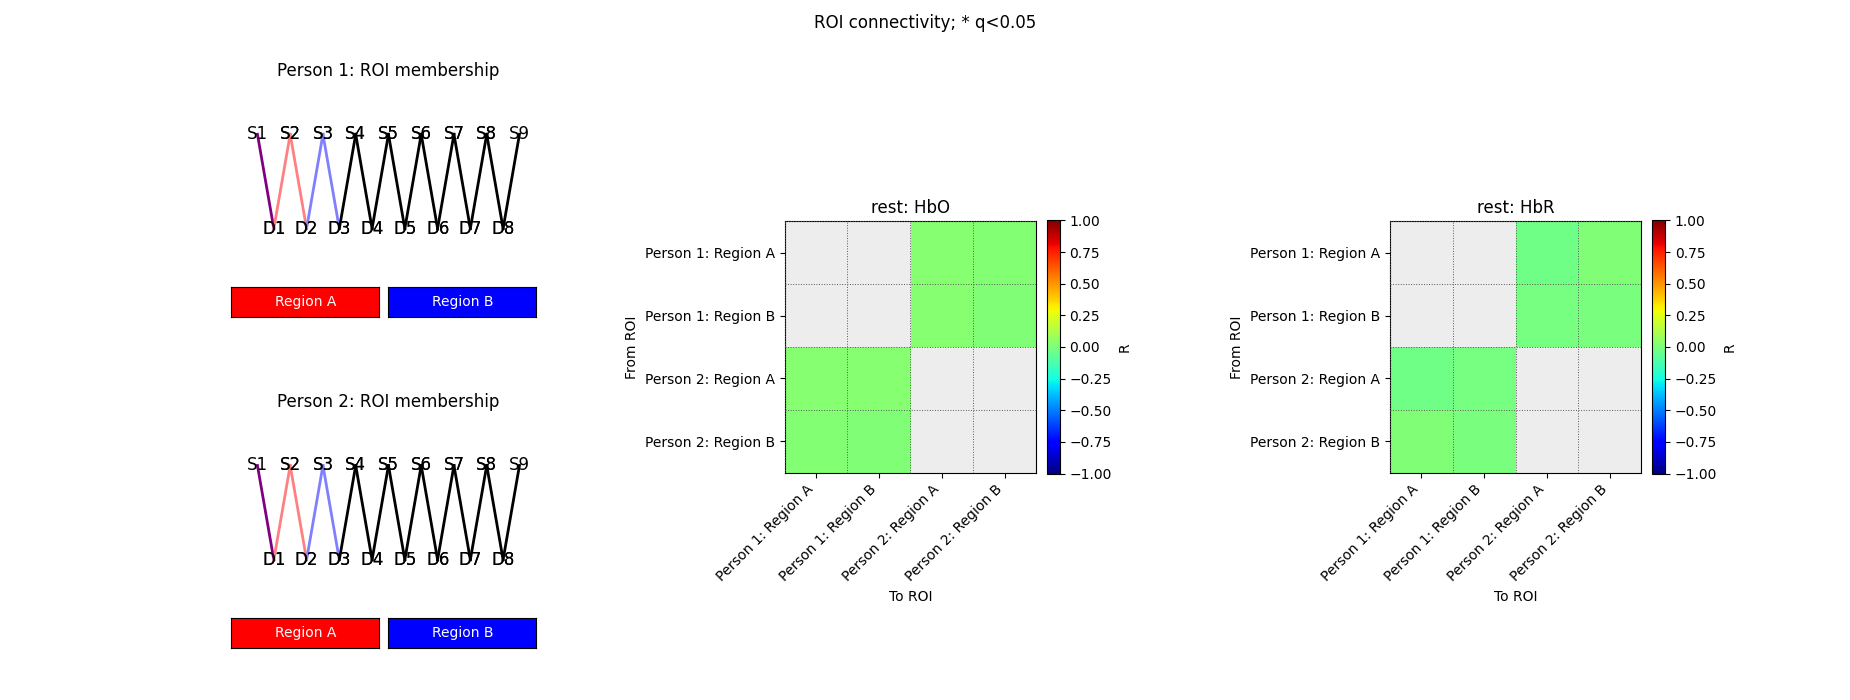

In [11]:
hyper_job = hyperscanning()
hyper_job.inputName = 'conc_roi'
hyper_job.options['grouping_variable'] = 'pair'
hyper_job.options['short_separation_correction'] = False
hyper_job.options['AR'] = 4
hyper_job.run(rest_dset)
roi_hyper = rest_dset.dataset[0]['hyperconn']
assert set(roi_hyper.geoROI) == {'Person 1', 'Person 2'}
display(roi_hyper.matrix(type_to='HbO'))
hyper_connectivity_figure = roi_hyper.show(threshold_type='q', thres=0.05)
plt.show()

## Browse the same results in NIRSViewIR

To open the dataset in the desktop viewer, run:

```python
from pyBrainAnalyzIR.vis.NIRSviewIR import NIRSviewIR
viewer = NIRSviewIR(dset)
```

Select a recording, then choose `amp_roi` (or another regional time course) in **Data type**. Click its region buttons to compare signals. Choose `stats_roi` for individual GLM results, or `Group: groupstats_roi` for the mixed-effects results. Statistics use the same probe colors, beta/error bars, and fixed region color keys as the figures above. Use the Condition, Type, P, and Q controls to explore results; when no significance filter is set, ROI figures mark `p<0.05`. ROI bars always show beta, so the t-statistic/beta display selector is disabled for them.

## Check a masked sample

Here we work on a copy of one recording. Excluding one channel at a particular time leaves the other channels in that region available. Excluding all channels in that region marks its sample as missing.

In [12]:
import copy
import xarray as xr
from pyBrainAnalyzIR.dataclasses.roi import quality_masks

masked_rec = copy.deepcopy(rec)
good = xr.ones_like(masked_rec['amp'].isel(wavelength=0, drop=True), dtype=bool)
good.values[20, 0] = False
good.values[21, :3] = False
masked_rec.set_mask('example_quality', good)
roi_average(masked_rec, roi_table, output_name='amp_roi_masked',
            roi_name='mask_example', weighted=False)
regional = masked_rec['amp_roi_masked']
assert np.isfinite(regional.pint.magnitude[20, 0]).all()
assert np.isnan(regional.pint.magnitude[21, 0]).all()
assert not quality_masks(masked_rec, regional)['roi_valid'].values[21, 0]
print('The ROI mask reflects the available contributing channels.')

The ROI mask reflects the available contributing channels.
